# 07 - Trực quan hóa dữ liệu Pima Indians Diabetes

Mục tiêu: bài tập thực hành 2 (mục 1.2.3), phần dữ liệu bệnh tiểu đường.

## 1. Load data và xử lý giá trị 0

=== Pima Diabetes (sau khi điền median) ===
Shape: (768, 10)
Số dòng trùng lặp: 0
Giá trị thiếu theo cột:
  Không có giá trị thiếu


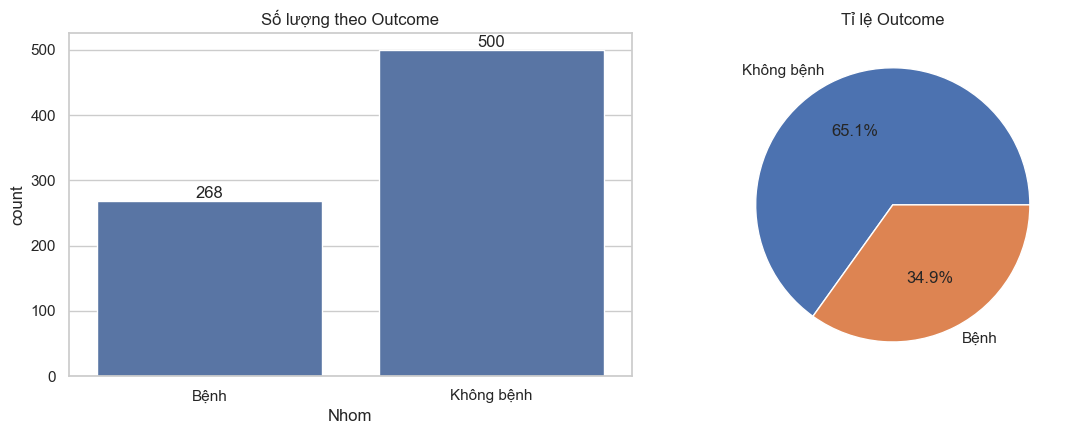

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

pima = pd.read_csv(can_file('pima_diabetes.csv', 'diabetes.csv'))
if 'Glucose' not in pima.columns:
    raise ValueError('File này không phải Pima Indians Diabetes (thiếu cột Glucose). Đặt file Pima vào data/pima_diabetes.csv.')
cot_khong_the_bang_0 = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
pima_raw = pima.copy()
pima[cot_khong_the_bang_0] = pima[cot_khong_the_bang_0].replace(0, np.nan)
for c in cot_khong_the_bang_0:
    pima[c] = pima[c].fillna(pima[c].median())
pima['Nhom'] = pima['Outcome'].map({0: 'Không bệnh', 1: 'Bệnh'})
features = [c for c in pima.columns if c not in ('Outcome', 'Nhom')]
kiem_tra_chat_luong(pima, 'Pima Diabetes (sau khi điền median)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=pima, x='Nhom', ax=axes[0]); axes[0].bar_label(axes[0].containers[0]); axes[0].set_title('Số lượng theo Outcome')
pima['Nhom'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[1]); axes[1].set_ylabel(''); axes[1].set_title('Tỉ lệ Outcome')
luu_hinh('07_pima_outcome')

## 2. Phân bố từng biến, tách màu theo Outcome

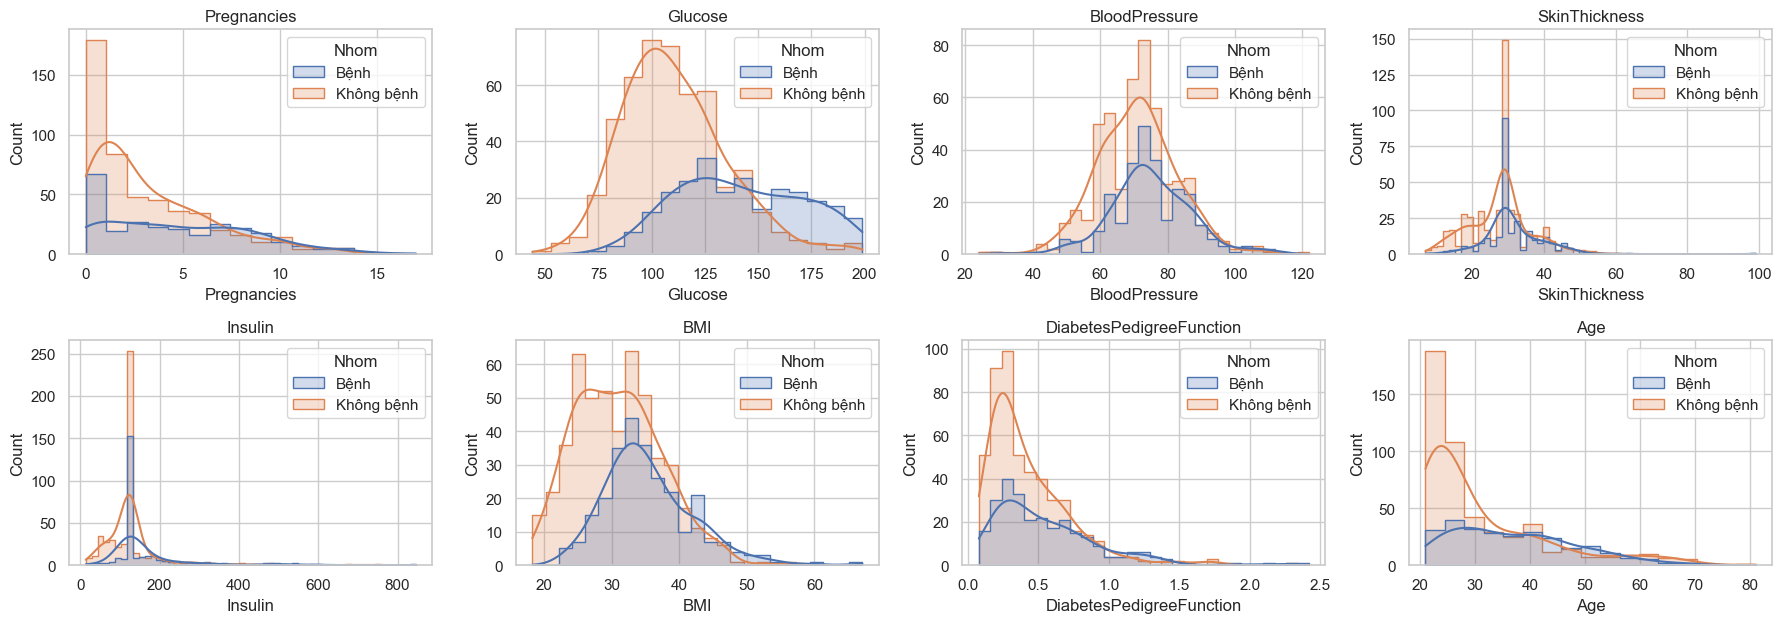

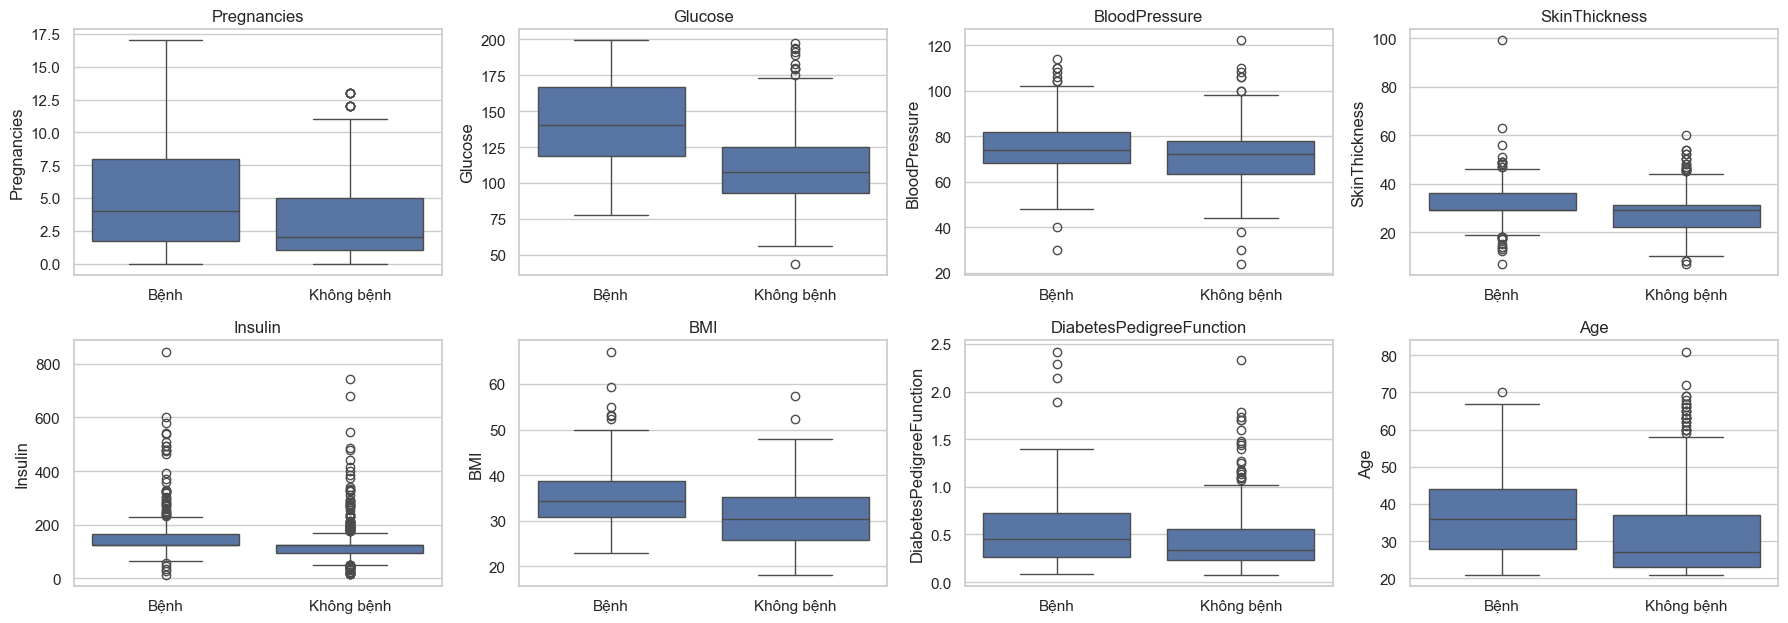

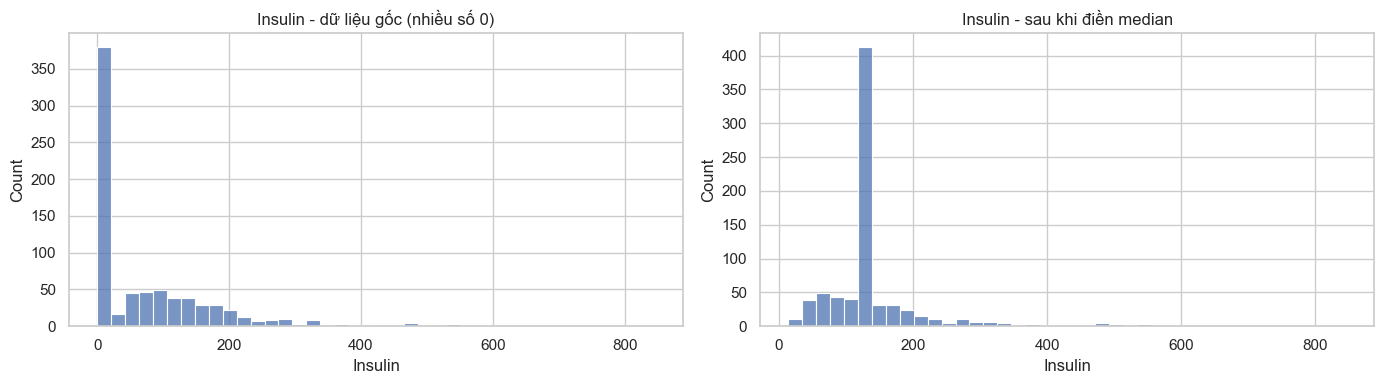

In [2]:
def ve_hist(ax, c):
    sns.histplot(data=pima, x=c, hue='Nhom', kde=True, element='step', ax=ax); ax.set_title(c)

def ve_box(ax, c):
    sns.boxplot(data=pima, x='Nhom', y=c, ax=ax); ax.set_title(c); ax.set_xlabel('')

luoi(features, ve_hist); luu_hinh('07_pima_histograms_by_outcome')
luoi(features, ve_box); luu_hinh('07_pima_boxplots_by_outcome')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(pima_raw['Insulin'], bins=40, ax=axes[0]); axes[0].set_title('Insulin - dữ liệu gốc (nhiều số 0)')
sns.histplot(pima['Insulin'], bins=40, ax=axes[1]); axes[1].set_title('Insulin - sau khi điền median')
luu_hinh('07_pima_insulin_before_after')

## 3. Quan hệ giữa các biến

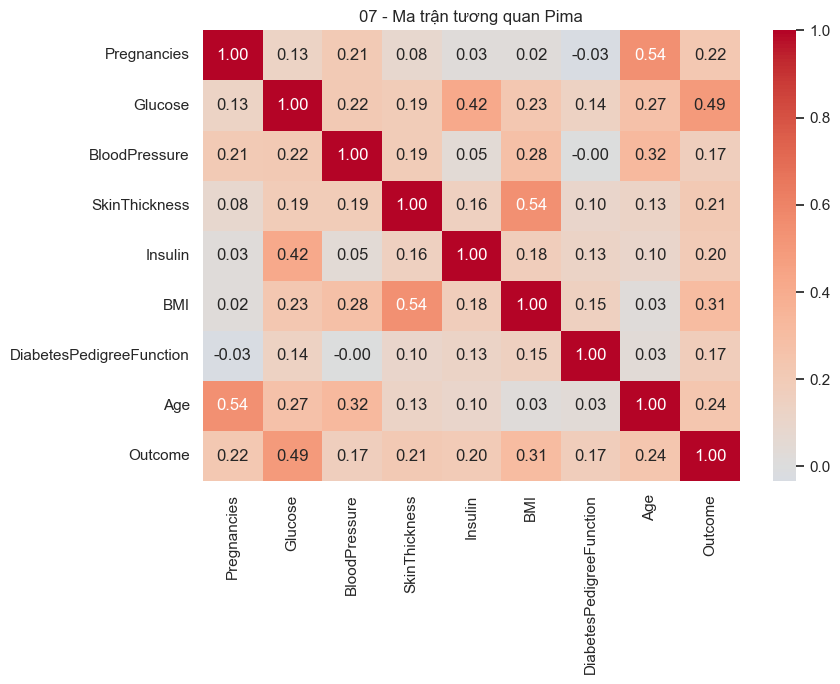

Tương quan với Outcome:
Glucose                     0.493
BMI                         0.312
Age                         0.238
Pregnancies                 0.222
SkinThickness               0.215
Insulin                     0.204
DiabetesPedigreeFunction    0.174
BloodPressure               0.166
Name: Outcome, dtype: float64


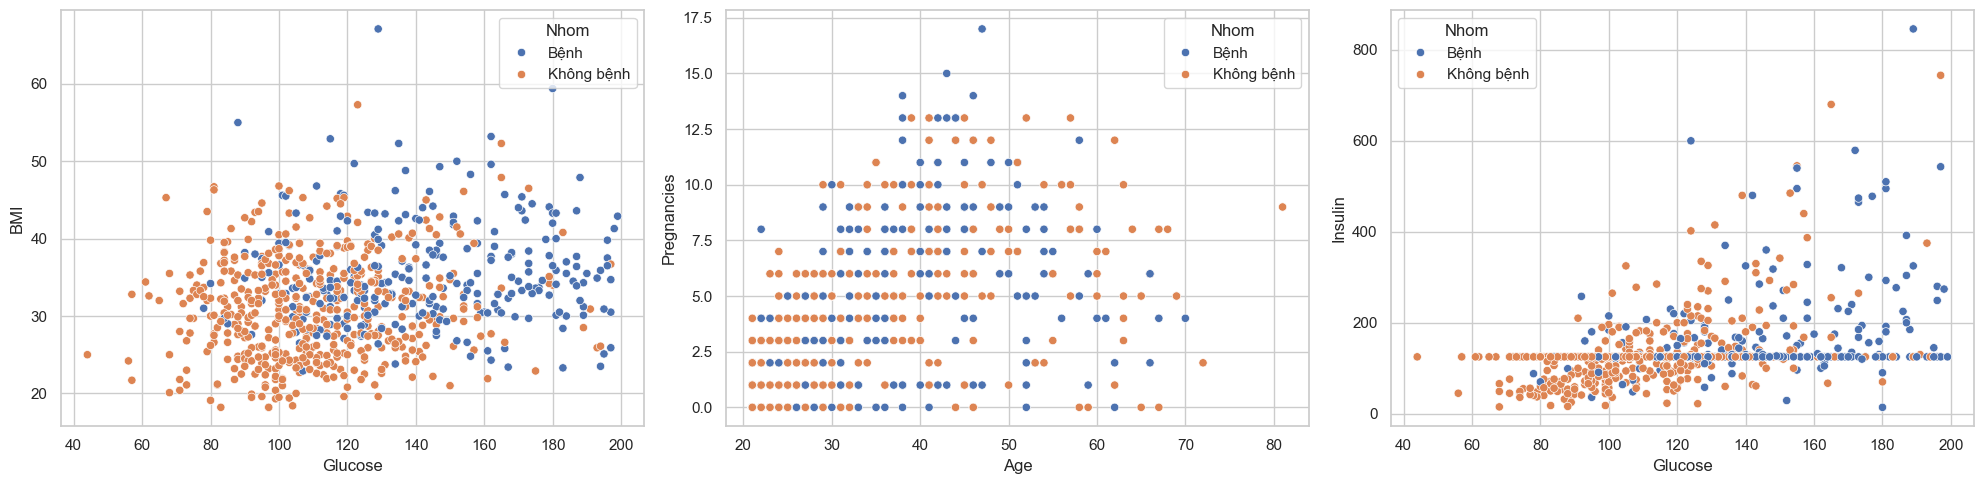

Tỉ lệ mắc bệnh (%) theo nhóm tuổi:
NhomTuoi
21-30    21.6
31-40    48.4
41-50    56.6
>50      46.9
Name: Outcome, dtype: float64


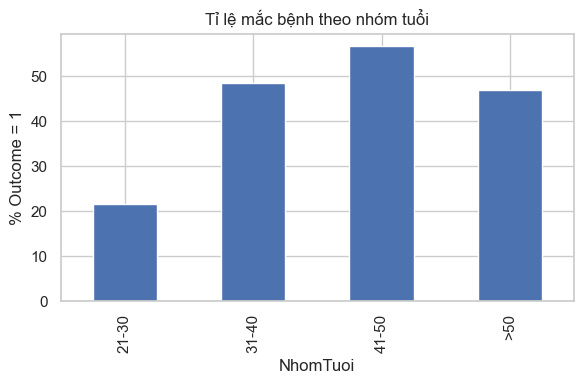

Đã cập nhật: results_summary.csv


In [3]:
corr = pima[features + ['Outcome']].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('07 - Ma trận tương quan Pima')
luu_hinh('07_pima_corr_heatmap')
print('Tương quan với Outcome:'); print(corr['Outcome'].drop('Outcome').sort_values(ascending=False).round(3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(data=pima, x='Glucose', y='BMI', hue='Nhom', ax=axes[0])
sns.scatterplot(data=pima, x='Age', y='Pregnancies', hue='Nhom', ax=axes[1])
sns.scatterplot(data=pima, x='Glucose', y='Insulin', hue='Nhom', ax=axes[2])
luu_hinh('07_pima_scatter')

pima['NhomTuoi'] = pd.cut(pima['Age'], bins=[20, 30, 40, 50, 90], labels=['21-30', '31-40', '41-50', '>50'])
ty_le_tuoi = pima.groupby('NhomTuoi', observed=True)['Outcome'].mean().mul(100).round(1)
print('Tỉ lệ mắc bệnh (%) theo nhóm tuổi:'); print(ty_le_tuoi)
plt.figure(figsize=(6, 4)); ty_le_tuoi.plot.bar(); plt.ylabel('% Outcome = 1'); plt.title('Tỉ lệ mắc bệnh theo nhóm tuổi')
luu_hinh('07_pima_outcome_by_age_group')
cap_nhat_summary('07_diabetes_viz', 'Pima Indians Diabetes', pima[features + ['Outcome']])

## 4. Nhận xét

Tách màu theo `Outcome` cho thấy biến nào có phân bố hai nhóm lệch xa nhau (thường là Glucose), đây là ứng viên tốt cho mô hình phân loại. Biểu đồ trước/sau của Insulin cho thấy cột giá trị 0 giả biến mất sau khi điền median, nhưng cũng tạo một đỉnh nhân tạo tại median; trong thực tế nên cân nhắc cách điền theo nhóm hoặc mô hình hóa. Tỉ lệ mắc bệnh theo nhóm tuổi cho thấy xu hướng theo tuổi (không phải quan hệ nhân quả).